# 📈 TATA MOTORS STOCK PRICE PREDICTION

### A Machine Learning Based Analysis and Prediction System

---

**Project Domain:** Machine Learning

**Programming Language:** Python

**Dataset:** Tata Motors Historical Stock Data

**Time Period:** Last 5 Years

**Model:** Linear Regression

**Tools:** Pandas, NumPy, Matplotlib, Scikit-learn

---

## Project Overview

This project aims to analyze historical stock market data
of Tata Motors and develop a machine learning model to
predict stock closing prices.

The project includes data collection, preprocessing,
exploratory data analysis, visualization, model training
and performance evaluation.

## Project Objectives

1. Collect historical stock market data.
2. Analyze stock price trends.
3. Preprocess and visualize the dataset.
4. Build a machine learning prediction model.
5. Evaluate prediction performance.

In [1]:
# Import project libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

# Display settings
pd.set_option('display.max_columns', None)

print("Tata Motors Stock Price Prediction Project")
print("-----------------------------------------")
print("All libraries imported successfully!")

print("\nLibrary Versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("yfinance:", yf.__version__)

Tata Motors Stock Price Prediction Project
-----------------------------------------
All libraries imported successfully!

Library Versions:
NumPy: 2.5.4
Pandas: 2.2.3
yfinance: 1.8.0


## 1. Data Collection

In this section, we collect five years of historical stock
market data for Tata Motors Passenger Vehicles Limited
using the yfinance library.

The dataset contains daily stock information such as
Open, High, Low, Close, Adjusted Close and Volume.

In [2]:
# Download 5 years of Tata Motors historical stock data

ticker = "TMPV.NS"

stock_data = yf.download(
    ticker,
    period="5y",
    interval="1d",
    auto_adjust=False,
    progress=False
)

# Check whether data was downloaded
if stock_data.empty:
    print("No data downloaded. Please check the ticker or internet connection.")
else:
    print("Stock data downloaded successfully!")
    print("Company: Tata Motors Passenger Vehicles")
    print("Ticker:", ticker)
    print("Total records:", len(stock_data))

    display(stock_data.head())

Stock data downloaded successfully!
Company: Tata Motors Passenger Vehicles
Ticker: TMPV.NS
Total records: 1237


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS
Date,,,,,,
2021-11-09,496.517303,509.649994,520.650024,503.500000,505.000000,50458762
2021-11-10,497.588928,510.750000,515.950012,500.200012,506.250000,26615777
2021-11-11,490.477051,503.450012,519.000000,501.000000,510.000000,29256213
2021-11-12,493.984283,507.049988,509.549988,497.350006,506.950012,20731808
2021-11-15,492.425507,505.450012,514.900024,504.500000,506.250000,18014977


In [4]:
import os

# Create the dataset folder if it doesn't exist
os.makedirs("../dataset", exist_ok=True)

# Save stock data
stock_data.to_csv("../dataset/tata_motors_stock_data.csv")

print("Dataset saved successfully!")
print("File: tata_motors_stock_data.csv")

Dataset saved successfully!
File: tata_motors_stock_data.csv


In [5]:
# Inspect the dataset

print("Dataset Shape:", stock_data.shape)

print("\nFirst Date:", stock_data.index.min())
print("Last Date:", stock_data.index.max())

print("\nColumn Names:")
print(stock_data.columns)

print("\nFirst 5 Records:")
display(stock_data.head())

print("\nLast 5 Records:")
display(stock_data.tail())

Dataset Shape: (1237, 6)

First Date: 2021-11-09 00:00:00
Last Date: 2026-11-09 00:00:00

Column Names:
MultiIndex([('Adj Close', 'TMPV.NS'),
            (    'Close', 'TMPV.NS'),
            (     'High', 'TMPV.NS'),
            (      'Low', 'TMPV.NS'),
            (     'Open', 'TMPV.NS'),
            (   'Volume', 'TMPV.NS')],
           names=['Price', 'Ticker'])

First 5 Records:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS
Date,,,,,,
2021-11-09,496.517303,509.649994,520.650024,503.500000,505.000000,50458762
2021-11-10,497.588928,510.750000,515.950012,500.200012,506.250000,26615777
2021-11-11,490.477051,503.450012,519.000000,501.000000,510.000000,29256213
2021-11-12,493.984283,507.049988,509.549988,497.350006,506.950012,20731808
2021-11-15,492.425507,505.450012,514.900024,504.500000,506.250000,18014977



Last 5 Records:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS,TMPV.NS
Date,,,,,,
2026-11-03,276.700012,276.700012,278.200012,271.899994,273.350006,6461269
2026-11-04,278.500000,278.500000,281.350006,274.200012,276.200012,9293718
2026-11-05,293.700012,293.700012,296.350006,284.000000,284.000000,16264124
2026-11-06,292.000000,292.000000,292.299988,286.299988,292.299988,7506108
2026-11-09,295.000000,295.000000,296.000000,290.750000,295.600006,6786481


In [6]:
import os

os.makedirs("dataset", exist_ok=True)

stock_data.to_csv("dataset/tata_motors_stock_data.csv")

print("Dataset saved inside the project folder!")

Dataset saved inside the project folder!


In [7]:
# Clean column names

stock_data.columns = stock_data.columns.get_level_values(0)

# Reset date index
stock_data = stock_data.reset_index()

# Display cleaned dataset
print("Cleaned Column Names:")
print(stock_data.columns.tolist())

display(stock_data.head())

Cleaned Column Names:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-09,496.517303,509.649994,520.650024,503.500000,505.000000,50458762
1,2021-11-10,497.588928,510.750000,515.950012,500.200012,506.250000,26615777
2,2021-11-11,490.477051,503.450012,519.000000,501.000000,510.000000,29256213
3,2021-11-12,493.984283,507.049988,509.549988,497.350006,506.950012,20731808
4,2021-11-15,492.425507,505.450012,514.900024,504.500000,506.250000,18014977


In [8]:
# Check for missing values

print("Missing Values:")
print(stock_data.isnull().sum())

print("\nDuplicate Records:", stock_data.duplicated().sum())

print("\nDataset Information:")
stock_data.info()

Missing Values:
Price
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Duplicate Records: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1237 entries, 0 to 1236
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1237 non-null   datetime64[ns]
 1   Adj Close  1237 non-null   float64       
 2   Close      1237 non-null   float64       
 3   High       1237 non-null   float64       
 4   Low        1237 non-null   float64       
 5   Open       1237 non-null   float64       
 6   Volume     1237 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 67.8 KB


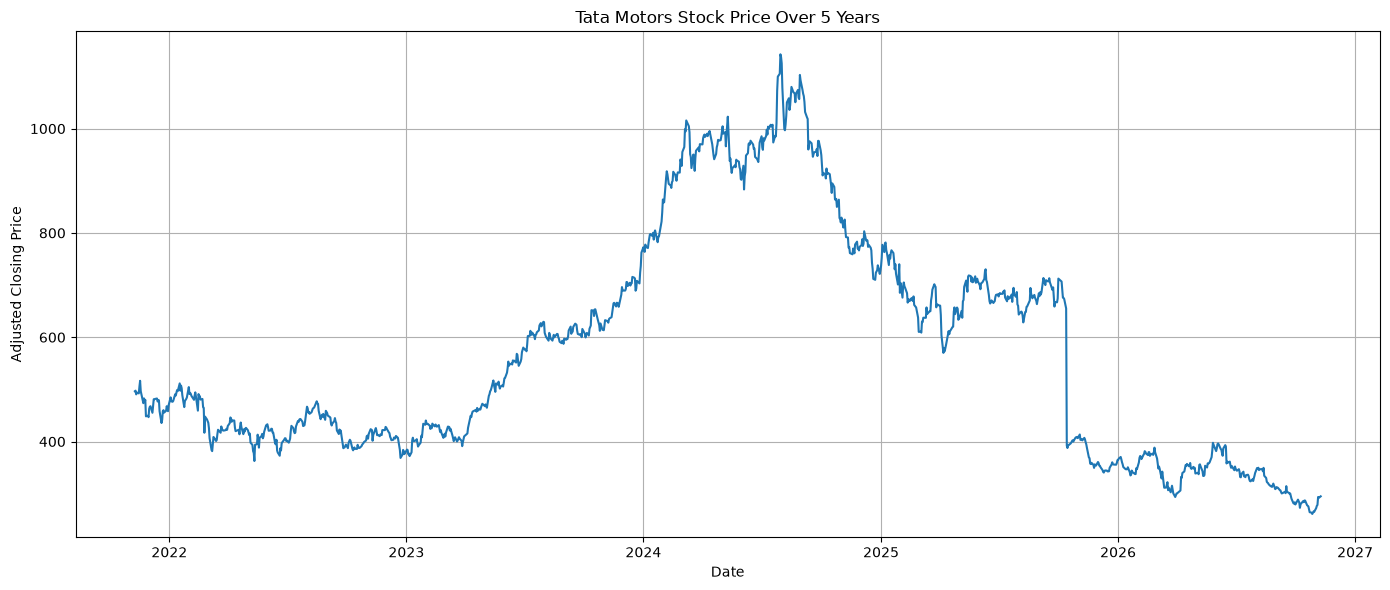

In [9]:
# Visualize stock price movement

plt.figure(figsize=(14, 6))

plt.plot(stock_data["Date"], stock_data["Adj Close"])

plt.title("Tata Motors Stock Price Over 5 Years")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price")

plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
# Select historical data before the demerger

model_data = stock_data[
    stock_data["Date"] <= "2025-10-23"
].copy()

print("Pre-Demerger Dataset")
print("--------------------")
print("Total records:", len(model_data))
print("First date:", model_data["Date"].min())
print("Last date:", model_data["Date"].max())

display(model_data.tail())

Pre-Demerger Dataset
--------------------
Total records: 979
First date: 2021-11-09 00:00:00
Last date: 2025-10-23 00:00:00


Price,Date,Adj Close,Close,High,Low,Open,Volume
974,2025-10-16,393.535492,396.799988,400.450012,389.549988,395.450012,21983752
975,2025-10-17,393.337158,396.600006,402.500000,392.250000,396.799988,16564547
976,2025-10-20,396.461243,399.750000,403.399994,396.600006,400.049988,10471672
977,2025-10-21,398.543976,401.850006,403.399994,400.049988,402.799988,3449156
978,2025-10-23,402.511047,405.850006,408.899994,403.600006,407.500000,14126009


In [11]:
# Save pre-demerger dataset

model_data.to_csv(
    "dataset/tata_motors_pre_demerger.csv",
    index=False
)

print("Pre-demerger dataset saved successfully!")
print("Total records:", len(model_data))

Pre-demerger dataset saved successfully!
Total records: 979


In [12]:
# Select input feature and target variable

model_data = model_data.sort_values("Date").copy()

model_data["Days"] = (
    model_data["Date"] - model_data["Date"].min()
).dt.days

X = model_data[["Days"]]
y = model_data["Adj Close"]

print("Input Feature (X): Days")
print("Target Variable (y): Adjusted Closing Price")

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

display(model_data[["Date", "Days", "Adj Close"]].head())

Input Feature (X): Days
Target Variable (y): Adjusted Closing Price

X Shape: (979, 1)
y Shape: (979,)


Price,Date,Days,Adj Close
0,2021-11-09,0,496.517303
1,2021-11-10,1,497.588928
2,2021-11-11,2,490.477051
3,2021-11-12,3,493.984283
4,2021-11-15,6,492.425507


In [13]:
# Split data into training and testing sets

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Period:")
print(model_data["Date"].iloc[0], "to",
      model_data["Date"].iloc[split_index - 1])

print("\nTesting Period:")
print(model_data["Date"].iloc[split_index], "to",
      model_data["Date"].iloc[-1])

Training Records: 783
Testing Records: 196

Training Period:
2021-11-09 00:00:00 to 2025-01-08 00:00:00

Testing Period:
2025-01-09 00:00:00 to 2025-10-23 00:00:00


In [14]:
# Import Linear Regression

from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")
print("Model Coefficient:", model.coef_[0])
print("Model Intercept:", model.intercept_)

Linear Regression model trained successfully!
Model Coefficient: 0.5654196013968943
Model Intercept: 297.87922873672


In [15]:
# Predict stock prices

y_pred = model.predict(X_test)

# Evaluate model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MODEL EVALUATION
-------------------------
Mean Absolute Error (MAE): 364.53
Mean Squared Error (MSE): 140809.18
Root Mean Squared Error (RMSE): 375.25
R2 Score: -34.3092


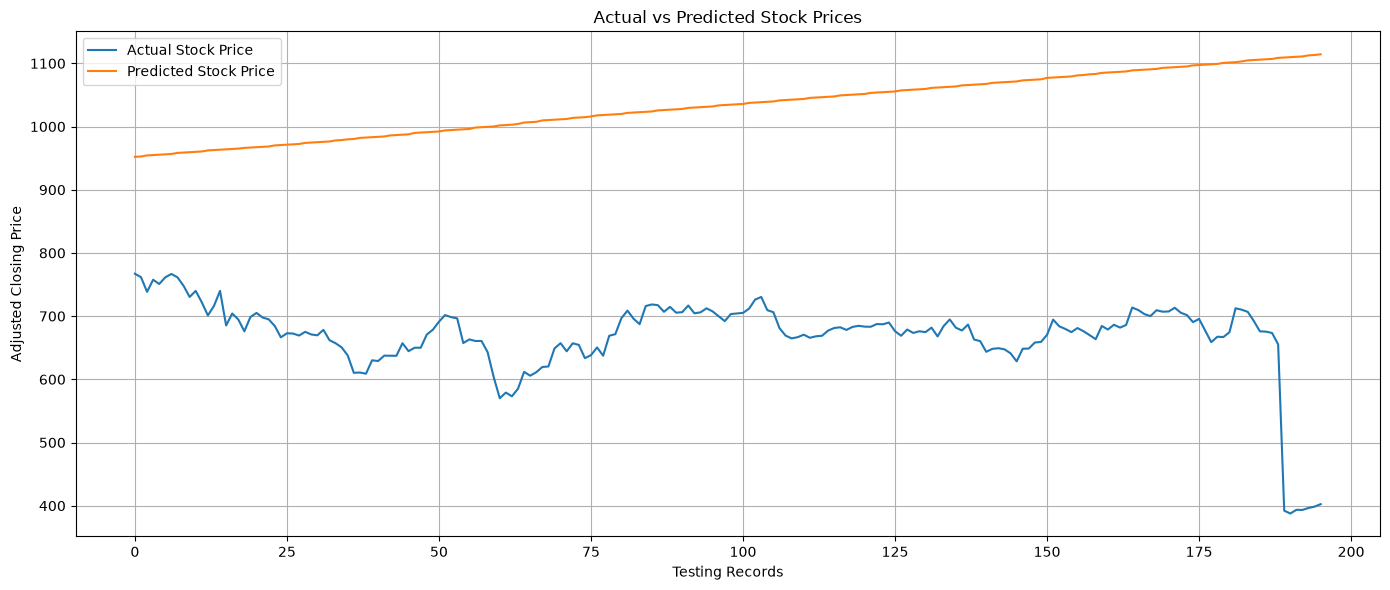

In [16]:
# Compare actual and predicted stock prices

plt.figure(figsize=(14, 6))

plt.plot(y_test.values, label="Actual Stock Price")
plt.plot(y_pred, label="Predicted Stock Price")

plt.title("Actual vs Predicted Stock Prices")
plt.xlabel("Testing Records")
plt.ylabel("Adjusted Closing Price")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
print("Last 15 Stock Records:")

display(
    model_data[["Date", "Adj Close", "Close"]].tail(15)
)

print("\nTraining and Testing Boundary:")
print("Last training date:", model_data["Date"].iloc[len(X_train) - 1])
print("First testing date:", model_data["Date"].iloc[len(X_train)])

Last 15 Stock Records:


Price,Date,Adj Close,Close
964,2025-10-01,712.440063,718.349976
965,2025-10-03,710.208557,716.099976
966,2025-10-06,706.786987,712.650024
967,2025-10-07,692.307068,698.049988
968,2025-10-08,675.942871,681.549988
969,2025-10-09,675.496521,681.099976
970,2025-10-10,673.364258,678.950012
971,2025-10-13,655.313965,660.750000
972,2025-10-14,392.196625,395.450012
973,2025-10-15,387.634460,390.850006



Training and Testing Boundary:
Last training date: 2025-01-08 00:00:00
First testing date: 2025-01-09 00:00:00


In [18]:
# Correct dataset by excluding demerger date and later records

model_data = stock_data[
    stock_data["Date"] <= "2025-10-13"
].copy()

model_data = model_data.sort_values("Date").reset_index(drop=True)

print("Corrected Dataset")
print("-----------------")
print("Total Records:", len(model_data))
print("First Date:", model_data["Date"].min())
print("Last Date:", model_data["Date"].max())

display(model_data.tail())

Corrected Dataset
-----------------
Total Records: 972
First Date: 2021-11-09 00:00:00
Last Date: 2025-10-13 00:00:00


Price,Date,Adj Close,Close,High,Low,Open,Volume
967,2025-10-07,692.307068,698.049988,712.900024,697.150024,712.650024,13099357
968,2025-10-08,675.942871,681.549988,702.000000,679.000000,694.900024,16568975
969,2025-10-09,675.496521,681.099976,685.000000,668.799988,684.599976,16202851
970,2025-10-10,673.364258,678.950012,688.599976,666.900024,684.799988,16069904
971,2025-10-13,655.313965,660.750000,679.400024,658.099976,679.000000,33288645


In [19]:
# Recreate numerical date feature

model_data["Days"] = (
    model_data["Date"] - model_data["Date"].min()
).dt.days

# Select input and target

X = model_data[["Days"]]
y = model_data["Adj Close"]

# Split into training and testing data (80:20)

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Last Training Date:", model_data["Date"].iloc[split_index - 1])
print("First Testing Date:", model_data["Date"].iloc[split_index])

Training Records: 777
Testing Records: 195
Last Training Date: 2024-12-31 00:00:00
First Testing Date: 2025-01-01 00:00:00


In [20]:
# Create and train the corrected model

model = LinearRegression()

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Corrected Linear Regression Model Trained Successfully!")
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Corrected Linear Regression Model Trained Successfully!
Coefficient: 0.5728989742814954
Intercept: 295.02892985888275


In [21]:
# Evaluate corrected model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("CORRECTED MODEL EVALUATION")
print("--------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

CORRECTED MODEL EVALUATION
--------------------------
MAE: 353.15
MSE: 128972.81
RMSE: 359.13
R2 Score: -87.8501


In [22]:
# Create previous day's closing price

model_data["Previous Close"] = model_data["Adj Close"].shift(1)

# Remove the first row containing a missing value

model_data = model_data.dropna().reset_index(drop=True)

print("New feature created successfully!")

display(
    model_data[["Date", "Adj Close", "Previous Close"]].head()
)

New feature created successfully!


Price,Date,Adj Close,Previous Close
0,2021-11-10,497.588928,496.517303
1,2021-11-11,490.477051,497.588928
2,2021-11-12,493.984283,490.477051
3,2021-11-15,492.425507,493.984283
4,2021-11-16,505.675049,492.425507


In [23]:
# Select input feature and target variable

X = model_data[["Previous Close"]]
y = model_data["Adj Close"]

# Split data into training and testing sets

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Improved Model Dataset")
print("----------------------")
print("Input Features:", X.columns.tolist())
print("Target Variable: Adj Close")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Improved Model Dataset
----------------------
Input Features: ['Previous Close']
Target Variable: Adj Close
Training Records: 776
Testing Records: 195


In [24]:
# Select input feature and target variable

X = model_data[["Previous Close"]]
y = model_data["Adj Close"]

# Split data chronologically (80% training, 20% testing)

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Linear Regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# Predict stock prices

y_pred = model.predict(X_test)

print("Improved model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Improved model trained successfully!
Training records: 776
Testing records: 195


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("IMPROVED MODEL EVALUATION")
print("-------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

IMPROVED MODEL EVALUATION
-------------------------
Mean Absolute Error (MAE): 9.96
Mean Squared Error (MSE): 178.4
Root Mean Squared Error (RMSE): 13.36
R2 Score: 0.8771


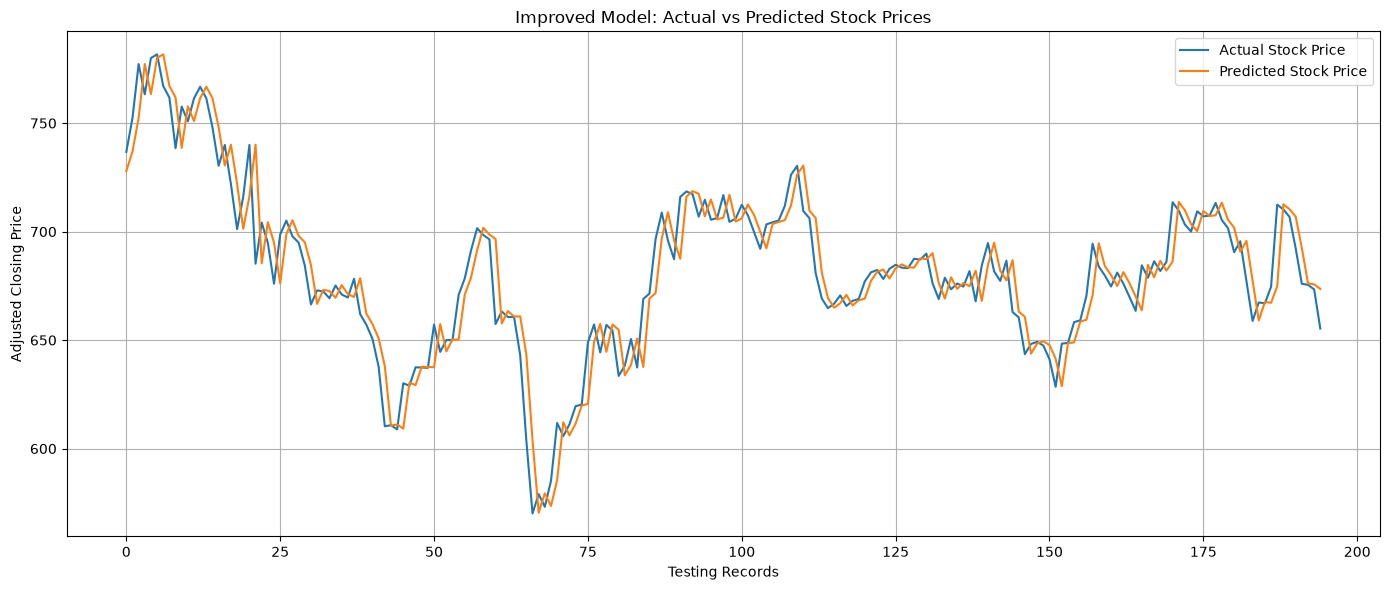

In [27]:
# Actual vs Predicted Stock Prices

plt.figure(figsize=(14, 6))

plt.plot(y_test.values, label="Actual Stock Price")
plt.plot(y_pred, label="Predicted Stock Price")

plt.title("Improved Model: Actual vs Predicted Stock Prices")
plt.xlabel("Testing Records")
plt.ylabel("Adjusted Closing Price")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
# Compare actual and predicted stock prices

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

print("ACTUAL VS PREDICTED STOCK PRICES")

display(comparison.tail(10).round(2))

ACTUAL VS PREDICTED STOCK PRICES


,Actual Price,Predicted Price,Difference
185,666.97,667.59,-0.62
186,674.60,667.19,7.41
187,712.44,674.82,37.62
188,710.21,712.59,-2.38
189,706.79,710.37,-3.58
190,692.31,706.95,-14.64
191,675.94,692.49,-16.55
192,675.50,676.15,-0.66
193,673.36,675.71,-2.34
194,655.31,673.58,-18.27


In [29]:
import joblib
import os

# Create model folder
os.makedirs("models", exist_ok=True)

# Retrain using all available pre-demerger data
X_all = model_data[["Previous Close"]]
y_all = model_data["Adj Close"]

final_model = LinearRegression()
final_model.fit(X_all, y_all)

# Save trained model
joblib.dump(final_model, "models/stock_price_model.pkl")

print("Final model saved successfully!")
print("Location: models/stock_price_model.pkl")

Final model saved successfully!
Location: models/stock_price_model.pkl
